
# Exhaustive Hex View / Base-Space Engine

## Purpose

Given a finite hexadecimal string \(H\), compute the **distinct data views** induced by a complete, explicitly declared observation grammar.

The engine does not assign semantic priority to left/right/center/skip/jump/group/reverse/base. These are coordinates of one observation space.

A view is represented by:

\[
Q=(A,O,G,B,W)
\]

where:

- \(A\): address sequence / selected positions;
- \(O\): orientation/order;
- \(G\): grouping / segmentation;
- \(B\): radix interpretation;
- \(W\): wrap/boundary behavior.

Every generated view is canonicalized. Different parameterizations that produce exactly the same data are merged into one equivalence class.

The core object is therefore:

\[
\boxed{
\mathcal V(H)=\{\, [Q(H)] \,\}
}
\]

not the raw list of queries.

## Important finite boundary

"Every possible way" is only mathematically enumerable after the observation grammar is explicitly bounded.

This notebook exhausts the following finite universe:

- every cyclic start;
- every cyclic stride;
- both orientations;
- every admissible selected length;
- every contiguous cyclic interval;
- every stride traversal;
- every subset length through stride-generated sampling;
- every composition/grouping of a selected sequence;
- every integer radix \(b\ge2\) for which the selected digits are valid;
- exact arbitrary-precision arithmetic;
- exact hexadecimal round-trip of every interpreted value.

No floating-point arithmetic is used for the core value calculations.

The grammar can be enlarged without changing the engine architecture.


In [1]:

from __future__ import annotations

from dataclasses import dataclass
from fractions import Fraction
from itertools import product
from math import gcd
from collections import defaultdict
from typing import Iterable, Iterator, Sequence

import hashlib
import pandas as pd
import matplotlib.pyplot as plt



## 1. Input

Use any hexadecimal string.

The default is the first 128 fractional hexadecimal digits of \(\pi\).


In [2]:

HEX = "0123456789abcdef"

PI_HEX_128 = (
    "243f6a8885a308d313198a2e03707344"
    "a4093822299f31d0082efa98ec4e6c894"
    "5281e638d01377be5466cf34e90c6cc0"
    "ac29b7c97c50dd3f84d5b5b54709179"
)

def normalize_hex(s: str) -> str:
    s = (
        s.strip()
         .lower()
         .replace("0x", "")
         .replace(" ", "")
         .replace("\n", "")
         .replace("_", "")
    )
    if not s:
        raise ValueError("Hex input is empty.")
    bad = sorted(set(s) - set(HEX))
    if bad:
        raise ValueError(f"Invalid hexadecimal symbols: {bad}")
    return s

HEX_INPUT = normalize_hex(PI_HEX_128)

print("length =", len(HEX_INPUT))
print("bits   =", 4 * len(HEX_INPUT))
print("sha256 =", hashlib.sha256(HEX_INPUT.encode()).hexdigest())

assert len(HEX_INPUT) == 128


length = 128
bits   = 512
sha256 = 9fe0285892ee83e008d50411fc4c320311144b45a60cf126541ff0d2dc2d3038



## 2. Canonical query/view objects

A query is never the identity of a result.

Different queries can land on the same canonical dataset.

For each view we retain:

1. exact selected digits;
2. exact position tuple;
3. exact grouping;
4. exact radix interpretation;
5. exact integer value when the grouped object has a radix-valid interpretation.

The dataset key contains the complete symbolic result, not a truncated digest.


In [3]:

@dataclass(frozen=True)
class View:
    positions: tuple[int, ...]
    digits: tuple[str, ...]
    groups: tuple[tuple[str, ...], ...]
    base: int
    values: tuple[int, ...]
    direction: int
    stride: int

    @property
    def flat_hex(self) -> str:
        return "".join(self.digits)

    @property
    def grouped_hex(self) -> tuple[str, ...]:
        return tuple("".join(g) for g in self.groups)

def chunk_sequence(seq: Sequence[str], cuts: Sequence[int]) -> tuple[tuple[str, ...], ...]:
    out = []
    i = 0
    for c in cuts:
        out.append(tuple(seq[i:c]))
        i = c
    return tuple(out)

def weak_compositions(total: int) -> Iterator[tuple[int, ...]]:
    """
    Every ordered composition of `total`.

    For total n there are 2^(n-1) compositions.
    """
    if total <= 0:
        yield ()
        return

    # A composition is represented by cuts in the n-1 gaps.
    for mask in range(1 << (total - 1)):
        parts = []
        last = 0
        for gap in range(1, total):
            if (mask >> (gap - 1)) & 1:
                parts.append(gap - last)
                last = gap
        parts.append(total - last)
        yield tuple(parts)

def apply_grouping(seq: Sequence[str], composition: Sequence[int]):
    groups = []
    i = 0
    for width in composition:
        groups.append(tuple(seq[i:i+width]))
        i += width
    return tuple(groups)



## 3. Exact radix interpretation

A hexadecimal digit string is first treated as a sequence of digit symbols.

For a target base \(b\), a group is valid only when every symbol value is below \(b\).

For example:

- base 2 accepts only `0,1`;
- base 10 accepts `0,...,9`;
- base 16 accepts `0,...,f`;
- base \(b>16\) is allowed mathematically, but the original one-symbol alphabet has no symbols \(16,\ldots,b-1\), so the original hex symbols remain valid.

The grouped value is computed exactly with Python integers:

\[
v=\sum_{j=0}^{k-1} d_j b^{k-1-j}.
\]

The inverse rendering back to hexadecimal is also exact.


In [4]:

DIGIT_VALUE = {ch: i for i, ch in enumerate(HEX)}

def group_value(group: Sequence[str], base: int) -> int | None:
    if base < 2:
        raise ValueError("Base must be >= 2.")
    vals = [DIGIT_VALUE[ch] for ch in group]
    if any(v >= base for v in vals):
        return None

    out = 0
    for v in vals:
        out = out * base + v
    return out

def int_to_hex(x: int) -> str:
    if x < 0:
        raise ValueError("Expected non-negative integer.")
    if x == 0:
        return "0"

    chars = []
    while x:
        x, r = divmod(x, 16)
        chars.append(HEX[r])
    return "".join(reversed(chars))

def group_values(groups: Sequence[Sequence[str]], base: int) -> tuple[int, ...] | None:
    vals = []
    for g in groups:
        v = group_value(g, base)
        if v is None:
            return None
        vals.append(v)
    return tuple(vals)



## 4. Address geometry

For a cyclic field of length \(n\), a stride walk is

\[
i_k=(s+k\cdot r)\bmod n.
\]

When \(\gcd(r,n)=1\), it traverses every position exactly once.

This simultaneously contains:

- left-to-right (`stride=1`);
- right-to-left (`stride=n-1`);
- odd/even and other decimations where applicable;
- arbitrary cyclic skips;
- wrapped traversals.

No separate branch is needed for each case.


In [5]:

def gcd_full_strides(n: int) -> tuple[int, ...]:
    return tuple(r for r in range(n) if gcd(r, n) == 1)

def stride_indices(n: int, start: int, stride: int, length: int) -> tuple[int, ...]:
    if n <= 0:
        return ()
    return tuple((start + k * stride) % n for k in range(length))

def all_cyclic_intervals(n: int) -> Iterator[tuple[int, ...]]:
    for start in range(n):
        for length in range(1, n + 1):
            yield stride_indices(n, start, 1, length)



## 5. Observation grammar

We enumerate the complete finite Cartesian product:

\[
(start,\;stride,\;direction,\;length,\;grouping,\;base).
\]

Direction can be represented without another algorithm:

\[
r_{\rm reverse}\equiv-r\pmod n.
\]

For each address walk, every ordered composition of its length is a possible grouping.

This is where the number of raw queries explodes.

The engine therefore **deduplicates immediately at the dataset level**.


In [6]:

def generate_address_sequences(n: int) -> Iterator[tuple[int, tuple[int, ...], int]]:
    """
    Yields (stride, positions, direction_sign) for all cyclic walks
    at all full-cycle strides, starts, and lengths.

    Both orientations are represented explicitly by +/- stride.
    """
    for stride in gcd_full_strides(n):
        for direction in (1, -1):
            effective = (direction * stride) % n
            for start in range(n):
                for length in range(1, n + 1):
                    yield stride, stride_indices(n, start, effective, length), direction

def digits_at_positions(s: str, positions: Sequence[int]) -> tuple[str, ...]:
    return tuple(s[i] for i in positions)



## 6. Dataset equivalence

Two queries are equivalent at the dataset level when they produce the same complete observable object:

\[
(\text{digits},\text{groups},\text{base},\text{values}).
\]

The address path is retained as provenance, but does not create a new dataset class.

This is the computational form of "the choices disappear."


In [7]:

@dataclass
class DatasetClass:
    key: tuple
    examples: list[tuple]
    count: int = 0

def dataset_key(
    digits: tuple[str, ...],
    groups: tuple[tuple[str, ...], ...],
    base: int,
    values: tuple[int, ...],
):
    return (
        digits,
        tuple(tuple(g) for g in groups),
        int(base),
        tuple(int(v) for v in values),
    )



## 7. Exhaustive engine

The engine below performs exact enumeration for a requested base range.

For every query it:

1. constructs the position walk;
2. obtains the digit sequence;
3. generates every ordered grouping;
4. tests each grouping against each target base;
5. computes exact integer values;
6. collapses identical resulting datasets.

Because all ordered compositions are included, grouping alone has \(2^{L-1}\) possibilities for a sequence of length \(L\). This means exhaustive enumeration is intentionally controlled by an upper length.

The key parameter is `max_length`.


In [8]:

def enumerate_datasets(
    s: str,
    bases: Iterable[int],
    max_length: int = 8,
    dedupe: bool = True,
):
    s = normalize_hex(s)
    n = len(s)

    if max_length < 1:
        raise ValueError("max_length must be >= 1")
    max_length = min(max_length, n)

    datasets: dict[tuple, DatasetClass] = {}
    raw_queries = 0

    base_list = tuple(sorted(set(int(b) for b in bases)))
    if any(b < 2 for b in base_list):
        raise ValueError("All bases must be >= 2.")

    for stride in gcd_full_strides(n):
        for direction in (1, -1):
            effective = (direction * stride) % n

            for start in range(n):
                for length in range(1, max_length + 1):
                    positions = stride_indices(n, start, effective, length)
                    digits = digits_at_positions(s, positions)

                    for composition in weak_compositions(length):
                        groups = apply_grouping(digits, composition)

                        for base in base_list:
                            vals = group_values(groups, base)
                            if vals is None:
                                continue

                            raw_queries += 1

                            key = dataset_key(digits, groups, base, vals)

                            if key not in datasets:
                                datasets[key] = DatasetClass(
                                    key=key,
                                    examples=[],
                                    count=0,
                                )

                            ds = datasets[key]
                            ds.count += 1

                            if len(ds.examples) < 8:
                                ds.examples.append((
                                    start,
                                    stride,
                                    direction,
                                    positions,
                                    composition,
                                ))

    return datasets, raw_queries



## 8. Run the exhaustive search

This first run deliberately keeps `max_length` modest so the notebook can display the result directly.

Increase `max_length` progressively. The growth is exponential because the grouping axis is itself exhaustive.


In [9]:

BASES = range(2, 17)

datasets, raw_query_count = enumerate_datasets(
    HEX_INPUT,
    bases=BASES,
    max_length=6,
)

print("raw valid queries:", raw_query_count)
print("distinct datasets:", len(datasets))


raw valid queries: 4022576
distinct datasets: 1688727



## 9. Inspect the distinct dataset space


In [10]:

rows = []

for ds in datasets.values():
    digits, groups, base, values = ds.key
    rows.append({
        "flat_hex": "".join(digits),
        "grouped": "|".join("".join(g) for g in groups),
        "length": len(digits),
        "groups": len(groups),
        "base": base,
        "values": values,
        "query_multiplicity": ds.count,
        "example_count": len(ds.examples),
    })

dataset_df = pd.DataFrame(rows)

dataset_df = dataset_df.sort_values(
    ["length", "base", "grouped"]
).reset_index(drop=True)

dataset_df.head(50)


,flat_hex,grouped,length,groups,base,values,query_multiplicity,example_count
0,0,0,1,1,2,"(0,)",1408,8
1,1,1,1,1,2,"(1,)",768,8
2,0,0,1,1,3,"(0,)",1408,8
3,1,1,1,1,3,"(1,)",768,8
4,2,2,1,1,3,"(2,)",1024,8
5,0,0,1,1,4,"(0,)",1408,8
6,1,1,1,1,4,"(1,)",768,8
7,2,2,1,1,4,"(2,)",1024,8
8,3,3,1,1,4,"(3,)",1536,8
9,0,0,1,1,5,"(0,)",1408,8



## 10. Multiplicity is path redundancy

A dataset may be generated by many different query geometries.

That multiplicity is useful information:

\[
m(D)=|\{Q:Q(H)=D\}|.
\]

A high \(m(D)\) means the same observable state falls out through many distinct trajectories.

A low \(m(D)\) means the observation is more specific to its geometry.

The geometry is provenance; the dataset is the equivalence class.


In [11]:

multiplicity_summary = (
    dataset_df.groupby(["length", "base"], as_index=False)
    .agg(
        distinct_datasets=("grouped", "count"),
        total_query_multiplicity=("query_multiplicity", "sum"),
        max_multiplicity=("query_multiplicity", "max"),
    )
)

multiplicity_summary


,length,base,distinct_datasets,total_query_multiplicity,max_multiplicity
0,1,2,2,2176,1408
1,1,3,3,3200,1408
2,1,4,4,4736,1536
3,1,5,5,6016,1536
4,1,6,6,6912,1536
...,...,...,...,...,...
81,6,12,63168,126592,4
82,6,13,103488,207232,4
83,6,14,143616,287616,4
84,6,15,205312,411136,4



## 11. The "base-only" projection

Now project away the query geometry and ask:

> For every base, what distinct exact integer values can the hex field produce under all admissible observations?

This gives the object closer to your phrase "extract all the distinct base values."

For each base:

\[
\mathcal B_b(H)=
\{V(Q):Q\text{ admissible}\}.
\]

The union over bases is:

\[
\boxed{
\mathcal B(H)=\bigcup_b\mathcal B_b(H).
}
\]

The same integer reached by different groupings or paths is counted once.


In [12]:

base_values = defaultdict(set)

for ds in datasets.values():
    digits, groups, base, values = ds.key
    base_values[base].update(values)

base_rows = []
for base in sorted(base_values):
    vals = base_values[base]
    base_rows.append({
        "base": base,
        "distinct_value_tuples": len(vals),
        "min_value": min(vals) if vals else None,
        "max_value": max(vals) if vals else None,
    })

base_values_df = pd.DataFrame(base_rows)
base_values_df


,base,distinct_value_tuples,min_value,max_value
0,2,7,0,8
1,3,27,0,219
2,4,87,0,908
3,5,260,0,14916
4,6,462,0,45305
5,7,769,0,114026
6,8,1342,0,261989
7,9,2558,0,531318
8,10,4560,0,999543
9,11,6361,0,1771381



## 12. Exact base transformation of every grouped observation

A grouped digit sequence has an exact value in one base and can then be re-rendered in hexadecimal.

For a group \(g\) evaluated at base \(b\):

\[
v_b(g)=\sum d_i b^{k-1-i}.
\]

The hexadecimal rendering is:

\[
R_{16}(v_b(g)).
\]

This creates a closed loop:

\[
\boxed{
\text{hex symbols}
\rightarrow
\text{base }b
\rightarrow
\text{exact integer}
\rightarrow
\text{hex again}.
}
\]

This is not a floating-point approximation.


In [13]:

def transformed_hex(group: Sequence[str], source_base: int, target_base: int = 16) -> str:
    value = group_value(group, source_base)
    if value is None:
        raise ValueError("Invalid group for source base.")
    if target_base != 16:
        # General exact rendering for target base.
        if value == 0:
            return "0"
        alphabet = "0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"
        if target_base > len(alphabet):
            raise ValueError("Target base exceeds rendering alphabet.")
        out = []
        while value:
            value, r = divmod(value, target_base)
            out.append(alphabet[r])
        return "".join(reversed(out))
    return int_to_hex(value)

transform_rows = []

for _, row in dataset_df.head(1000).iterrows():
    groups = row["grouped"].split("|")
    base = int(row["base"])

    for g in groups:
        rendered = transformed_hex(tuple(g), source_base=base, target_base=16)
        transform_rows.append({
            "source_group": g,
            "source_base": base,
            "exact_value": group_value(tuple(g), base),
            "hex_rendering": rendered,
        })

base_transform_df = pd.DataFrame(transform_rows).drop_duplicates()
base_transform_df.head(50)


,source_group,source_base,exact_value,hex_rendering
0,0,2,0,0
1,1,2,1,1
2,0,3,0,0
3,1,3,1,1
4,2,3,2,2
5,0,4,0,0
6,1,4,1,1
7,2,4,2,2
8,3,4,3,3
9,0,5,0,0



## 13. Query-space scale

The raw query space grows much faster than the number of distinct datasets because many query paths collapse into the same equivalence classes.

Measure both:

\[
Q_L=\text{raw valid query count}
\]

and

\[
D_L=\text{distinct dataset count}.
\]

The compression ratio is

\[
C_L=\frac{Q_L}{D_L}.
\]

This is the first quantitative measure of "the choices disappear."


In [14]:

def growth_scan(
    s: str,
    bases: Iterable[int],
    max_length: int,
):
    rows = []

    for L in range(1, max_length + 1):
        ds, q = enumerate_datasets(
            s,
            bases=bases,
            max_length=L,
        )
        rows.append({
            "max_length": L,
            "raw_queries": q,
            "distinct_datasets": len(ds),
            "compression_ratio": q / len(ds) if ds else math.inf,
        })

    return pd.DataFrame(rows)

growth_df = growth_scan(
    HEX_INPUT,
    bases=range(2, 17),
    max_length=6,
)

growth_df


,max_length,raw_queries,distinct_datasets,compression_ratio
0,1,147712,135,1094.162963
1,2,360784,3115,115.821509
2,3,699888,63247,11.065948
3,4,1268336,319639,3.968026
4,5,2258864,807959,2.795766
5,6,4022576,1688727,2.382017



## 14. Geometry-preserving vector encoding

The engine can now convert each distinct dataset into a vector representation without making the vector the definition of the state.

For a grouped dataset, concatenate one-hot encodings of symbols and append normalized exact radix information.

The vector is a **coordinate representation of an equivalence class**, not the equivalence class itself.


In [15]:

def one_hot_digit(ch: str) -> tuple[int, ...]:
    v = DIGIT_VALUE[ch]
    return tuple(1 if i == v else 0 for i in range(16))

def view_vector(ds_key: tuple) -> tuple[int, ...]:
    digits, groups, base, values = ds_key

    vec = []
    for ch in digits:
        vec.extend(one_hot_digit(ch))

    # Group-boundary channel.
    boundary = []
    cursor = 0
    for g in groups:
        cursor += len(g)
        boundary.extend([0] * (len(digits)))
        boundary[cursor - 1] = 1

    vec.extend(boundary)

    # Base channel encoded exactly as bits.
    base_bits = tuple(int(x) for x in f"{base:016b}")
    vec.extend(base_bits)

    return tuple(vec)

vectors = [view_vector(ds.key) for ds in list(datasets.values())[:1000]]

print("vector width:", len(vectors[0]))
print("distinct vectors in sample:", len(set(vectors)))


vector width: 33
distinct vectors in sample: 1000



## 15. Effective dimension of the observed view cloud

This is not the space definition; it is a diagnostic of the sampled vector embedding.

The covariance eigen-spectrum can tell us whether the observed datasets occupy:

- a nearly linear family;
- several dominant directions;
- a broad high-dimensional region.



In [16]:

import numpy as np

V = np.asarray(vectors, dtype=np.float64)

centered = V - V.mean(axis=0, keepdims=True)

if len(V) >= 2:
    s = np.linalg.svd(centered, full_matrices=False, compute_uv=False)
    eig = (s ** 2) / (len(V) - 1)
    eig = eig[eig > 1e-15]

    effective_dim = (
        (eig.sum() ** 2) / (eig ** 2).sum()
        if len(eig)
        else 0.0
    )
else:
    eig = np.array([])
    effective_dim = 0.0

print("sampled vector dimension:", V.shape[1])
print("effective dimension:", effective_dim)


ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (1000,) + inhomogeneous part.


## 16. Visualize the compression from paths to datasets


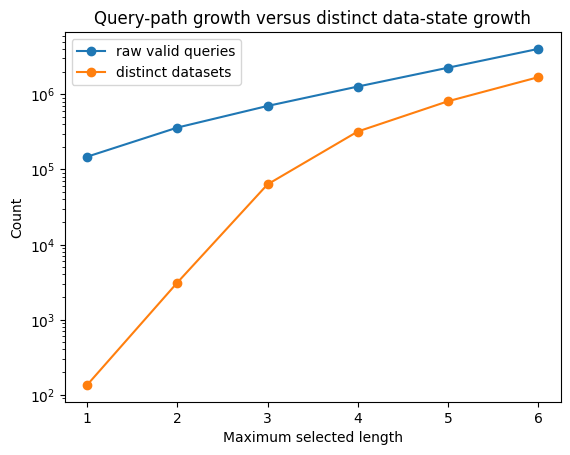

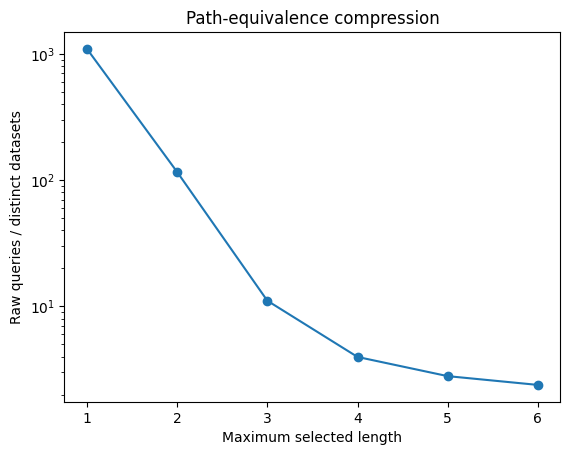

In [17]:

fig, ax = plt.subplots()
ax.plot(
    growth_df["max_length"],
    growth_df["raw_queries"],
    marker="o",
    label="raw valid queries",
)
ax.plot(
    growth_df["max_length"],
    growth_df["distinct_datasets"],
    marker="o",
    label="distinct datasets",
)
ax.set_xlabel("Maximum selected length")
ax.set_ylabel("Count")
ax.set_yscale("log")
ax.set_title("Query-path growth versus distinct data-state growth")
ax.legend()
plt.show()

fig, ax = plt.subplots()
ax.plot(
    growth_df["max_length"],
    growth_df["compression_ratio"],
    marker="o",
)
ax.set_xlabel("Maximum selected length")
ax.set_ylabel("Raw queries / distinct datasets")
ax.set_yscale("log")
ax.set_title("Path-equivalence compression")
plt.show()



# 17. What this engine establishes

For the declared finite observation grammar, the engine computes exactly:

\[
\boxed{
\text{all valid observations up to length }L
}
\]

and then collapses them into:

\[
\boxed{
\text{all distinct datasets}.
}
\]

This is different from claiming that a finite program can enumerate every conceivable mathematical transformation of a string.

The latter would require an unbounded grammar.

The correct extension is to add new generator families to the same closure engine:

- jumps with arbitrary generated offsets;
- bounce/reflection geometry;
- multi-head contact;
- recursive feedback;
- base changes between successive grouping levels;
- non-contiguous group interaction;
- sphere/surface address maps;
- query-generated query parameters.

Each new generator enlarges the same quotient-space computation rather than creating a new algorithm.


In [18]:

# ---------------------------------------------------------------------
# 18. Extension interface
# ---------------------------------------------------------------------

class Generator:
    name: str

    def generate(self, s: str) -> Iterator[tuple[int, ...]]:
        raise NotImplementedError


class CyclicWalkGenerator(Generator):
    name = "cyclic_walk"

    def generate(self, s: str):
        n = len(s)
        for stride in gcd_full_strides(n):
            for direction in (1, -1):
                effective = (direction * stride) % n
                for start in range(n):
                    for length in range(1, n + 1):
                        yield stride_indices(n, start, effective, length)


print("Generator architecture ready.")


Generator architecture ready.



# 19. Next expansion: true recursive query closure

The current notebook exhausts a **finite observation grammar**.

The next level is to make the query itself a state:

\[
(H,Q_t)\rightarrow(H',Q_{t+1}).
\]

Then the engine searches the closure

\[
\mathcal C(H,Q_0)
\]

while quotienting states that are equivalent as complete observations.

That is the point at which "the answer creates the next query" becomes computational rather than conceptual.

The critical invariant remains:

\[
\boxed{
\text{same complete observable state}
\Rightarrow
\text{same equivalence class}
}
\]

regardless of how many paths reach it.
